# LOAModel — Semana 6: AdaBoost con Google Drive

**Responsable:** Anthony  
**Fecha de referencia:** 09/11/2026  
**Objetivo:** ajustar y evaluar dos tareas complementarias sobre **el mismo dataset de Google Drive**:

- **Regresión:** predecir `total_homicidios` por distrito, fecha y franja horaria.
- **Clasificación binaria:** predecir `hubo_homicidios`, derivado de `total_homicidios > 0`.

**Ejecución prevista:** Google Colab con el Drive montado. No depende de la carpeta desde la que se abra el notebook ni de la raíz de GitHub. El CSV esperado es el generado por `Procesamiento_DatasetModelo.ipynb`.

> **Importante:** este notebook está configurado para el dataset de distrito-fecha-franja horaria de Drive. Los resultados históricos obtenidos con el panel diferente de cantón-día **no son comparables directamente** y no deben reutilizarse como métricas de este notebook. Los resultados se obtienen al ejecutar las celdas sobre el CSV de Drive.

## 1. Librerías y configuración reproducible

Si Google Colab informa que falta alguna dependencia, ejecute `%pip install -q pandas numpy scikit-learn matplotlib joblib` y vuelva a correr la celda.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, precision_recall_curve
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

SEMILLA = 42
np.random.seed(SEMILLA)
print('Python:', platform.python_version())
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)

Python: 3.13.18
scikit-learn: 1.6.1
pandas: 2.2.3


## 2. Montaje de Google Drive y rutas del proyecto

**Se conserva exactamente la ubicación de entrada utilizada por SVM y Decision Tree:** `MyDrive/ModelLOA/Datos_Procesados/dataset_homicidios_final.csv`. Los artefactos de este experimento se guardan en otra carpeta de **ese mismo Drive**, bajo `MyDrive/ModelLOA/Resultados/AdaBoost_Semana6`.

No se utiliza `Path.cwd()` ni se requieren los CSV de resultados del repositorio para ejecutar el entrenamiento.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

CARPETA_DRIVE = Path('/content/drive/MyDrive/ModelLOA/Datos_Procesados')
ARCHIVO_DATOS = CARPETA_DRIVE / 'dataset_homicidios_final.csv'
CARPETA_RESULTADOS = Path('/content/drive/MyDrive/ModelLOA/Resultados/AdaBoost_Semana6')

if not ARCHIVO_DATOS.is_file():
    raise FileNotFoundError(
        f'No se encontró el CSV en Google Drive: {ARCHIVO_DATOS}. '
        'Comprueba que montaste la cuenta de Drive correcta y que ejecutaste el procesamiento.'
    )
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
print('Entrada:', ARCHIVO_DATOS)
print('Resultados:', CARPETA_RESULTADOS)

Mounted at /content/drive
Entrada: /content/drive/MyDrive/ModelLOA/Datos_Procesados/dataset_homicidios_final.csv
Resultados: /content/drive/MyDrive/ModelLOA/Resultados/AdaBoost_Semana6


## 3. Lectura, controles de calidad y objetivos comunes

El CSV debe tener los campos de `Procesamiento_DatasetModelo.ipynb`. Se conservan los códigos geográficos como texto para evitar la pérdida de ceros a la izquierda. La categoría `categoria_incidencia` no se usa como predictor porque se deriva de la variable objetivo y causaría fuga de información.

In [3]:
COLUMNAS_EXIGIDAS = [
    'fecha', 'codigo_provincia', 'codigo_distrito', 'franja_horaria',
    'es_feriado', 'anio', 'mes', 'dia_semana_num', 'total_homicidios'
]
PREDICTORAS = [
    'codigo_provincia', 'codigo_distrito', 'franja_horaria',
    'es_feriado', 'anio', 'mes', 'dia_semana_num'
]
CATEGORICAS = ['codigo_provincia', 'codigo_distrito', 'franja_horaria']
NUMERICAS = ['es_feriado', 'anio', 'mes', 'dia_semana_num']
TARGET_REG = 'total_homicidios'
TARGET_CLF = 'hubo_homicidios'

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with ruta.open('rb') as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()

DF = pd.read_csv(
    ARCHIVO_DATOS, encoding='utf-8-sig',
    dtype={'codigo_provincia': 'string', 'codigo_distrito': 'string'},
    low_memory=False
)
faltantes = sorted(set(COLUMNAS_EXIGIDAS) - set(DF.columns))
if faltantes:
    raise ValueError(f'Columnas ausentes en el dataset de Drive: {faltantes}')

# El procesamiento existente exporta fechas en formato dd/mm/aaaa.
DF['fecha'] = pd.to_datetime(DF['fecha'], format='%d/%m/%Y', errors='coerce')
if DF['fecha'].isna().any():
    raise ValueError('Hay fechas vacías o distintas de dd/mm/aaaa. Revisar el CSV procesado.')

for col in CATEGORICAS:
    DF[col] = DF[col].astype('string').str.strip()
    if DF[col].isna().any() or DF[col].eq('').any():
        raise ValueError(f'La variable categórica {col} contiene valores vacíos.')

DF['es_feriado'] = DF['es_feriado'].astype('string').str.lower().map({
    'true': 1, 'false': 0, '1': 1, '0': 0
})
for col in NUMERICAS + [TARGET_REG]:
    DF[col] = pd.to_numeric(DF[col], errors='coerce')
if DF[PREDICTORAS + [TARGET_REG]].isna().any().any():
    raise ValueError('Existen valores nulos/no numéricos en predictoras u objetivo.')
if (DF[TARGET_REG] < 0).any() or not np.allclose(DF[TARGET_REG], np.round(DF[TARGET_REG])):
    raise ValueError('total_homicidios debe contener conteos enteros no negativos.')

CLAVE = ['codigo_provincia', 'codigo_distrito', 'fecha', 'franja_horaria']
if DF.duplicated(CLAVE).any():
    raise ValueError('Existen duplicados por provincia-distrito-fecha-franja.')
DF[TARGET_CLF] = (DF[TARGET_REG] > 0).astype('int8')
DF = DF.sort_values(CLAVE, kind='stable').reset_index(drop=True)
HASH_ENTRADA = sha256_archivo(ARCHIVO_DATOS)

resumen = pd.DataFrame([{
    'filas': len(DF),
    'distritos': DF['codigo_distrito'].nunique(),
    'desde': DF['fecha'].min().date().isoformat(),
    'hasta': DF['fecha'].max().date().isoformat(),
    'porcentaje_sin_homicidios': round((1-DF[TARGET_CLF].mean())*100,2),
}])
display(resumen)
print('SHA-256 de la fuente:', HASH_ENTRADA)
print('Distribución binaria:', DF[TARGET_CLF].value_counts().to_dict())

,filas,distritos,desde,hasta,porcentaje_sin_homicidios
0,2590560,140,2014-01-01,2026-08-31,98.61


SHA-256 de la fuente: a6ac09022c0242e42acd3c5d04c3c1afceccf1eb30a0b49e37c3e90affad8328
Distribución binaria: {0: 2554560, 1: 36000}


## 4. Protocolo temporal para las dos tareas

Se conserva un protocolo único para regresión y clasificación: subentrenamiento (antes de 2023), validación (2023–2024) y prueba (desde 2025). El test no participa en la selección de parámetros.

Para reducir consumo de RAM en Colab se establece un límite configurable de filas de **entrenamiento**. La selección es estratificada y determinista (semilla 42). **Validación y prueba no se muestrean.** Aumente los límites si cuenta con suficiente RAM. Estas cantidades deben registrarse al comparar experimentos.

In [4]:
FECHA_VALIDACION = pd.Timestamp('2023-01-01')
FECHA_TEST = pd.Timestamp('2025-01-01')
MAX_FILAS_SUBENTRENAMIENTO = 300_000  # Cambiable según RAM de Colab
MAX_FILAS_ENTRENAMIENTO_FINAL = 400_000

m_sub = DF['fecha'] < FECHA_VALIDACION
m_val = (DF['fecha'] >= FECHA_VALIDACION) & (DF['fecha'] < FECHA_TEST)
m_train = DF['fecha'] < FECHA_TEST
m_test = DF['fecha'] >= FECHA_TEST

for nombre, mask in [('Subentrenamiento',m_sub),('Validación',m_val),
                     ('Entrenamiento final',m_train),('Prueba',m_test)]:
    print(f'{nombre}: {int(mask.sum()):,} filas')
    if not mask.any():
        raise ValueError(f'{nombre} quedó vacío. Revisa el intervalo del dataset.')


def indices_entrenamiento(mascara, max_filas):
    indices = np.flatnonzero(mascara.to_numpy())
    if len(indices) <= max_filas:
        return indices
    y = DF.iloc[indices][TARGET_CLF].to_numpy()
    seleccion, _ = train_test_split(
        indices, train_size=max_filas, random_state=SEMILLA,
        stratify=y if np.unique(y).size == 2 else None
    )
    return np.sort(seleccion)

ix_sub = indices_entrenamiento(m_sub, MAX_FILAS_SUBENTRENAMIENTO)
ix_train = indices_entrenamiento(m_train, MAX_FILAS_ENTRENAMIENTO_FINAL)
ix_val = np.flatnonzero(m_val.to_numpy())
ix_test = np.flatnonzero(m_test.to_numpy())

def crear_preprocesador():
    return ColumnTransformer([
        ('categoricas', OneHotEncoder(handle_unknown='ignore', dtype=np.float32), CATEGORICAS),
        ('numericas', 'passthrough', NUMERICAS)
    ], sparse_threshold=1.0)

pre_val = crear_preprocesador()
X_sub = pre_val.fit_transform(DF.iloc[ix_sub][PREDICTORAS])
X_val = pre_val.transform(DF.iloc[ix_val][PREDICTORAS])
y_sub_reg = DF.iloc[ix_sub][TARGET_REG].to_numpy()
y_val_reg = DF.iloc[ix_val][TARGET_REG].to_numpy()
y_sub_clf = DF.iloc[ix_sub][TARGET_CLF].to_numpy()
y_val_clf = DF.iloc[ix_val][TARGET_CLF].to_numpy()

if len(np.unique(y_sub_clf)) < 2 or len(np.unique(y_val_clf)) < 2:
    raise ValueError('Se necesitan casos positivos y negativos en subentrenamiento y validación.')
print('Entrenamiento real seleccionado:', len(ix_sub), 'de',int(m_sub.sum()))
print('Codificación:', X_sub.shape, X_val.shape)

Subentrenamiento: 1,840,720 filas
Validación: 409,360 filas
Entrenamiento final: 2,250,080 filas
Prueba: 340,480 filas
Entrenamiento real seleccionado: 300000 de 1840720
Codificación: (300000, 172) (409360, 172)


## 5. Ajuste y selección de AdaBoostRegressor

Se ensayan tres combinaciones; se elige el menor **MAE de validación** (MSE en empate). El conteo predicho se limita a valores no negativos.

In [5]:
CANDIDATOS_REG = [
    {'id':'R1','n_estimators':12,'max_depth':2,'min_samples_leaf':200,'learning_rate':0.1,'loss':'linear'},
    {'id':'R2','n_estimators':20,'max_depth':3,'min_samples_leaf':150,'learning_rate':0.1,'loss':'linear'},
    {'id':'R3','n_estimators':28,'max_depth':2,'min_samples_leaf':250,'learning_rate':0.2,'loss':'square'},
]

def nuevo_reg(p):
    arbol = DecisionTreeRegressor(
        max_depth=p['max_depth'], min_samples_leaf=p['min_samples_leaf'], random_state=SEMILLA)
    return AdaBoostRegressor(
        estimator=arbol, n_estimators=p['n_estimators'],
        learning_rate=p['learning_rate'], loss=p['loss'], random_state=SEMILLA)

def met_reg(y, pred):
    return {
        'MSE': float(mean_squared_error(y,pred)),
        'MAE': float(mean_absolute_error(y,pred)),
        'R2': float(r2_score(y,pred))
    }

hist_reg = []
for config in CANDIDATOS_REG:
    inicio = time.perf_counter()
    model = nuevo_reg(config).fit(X_sub, y_sub_reg)
    pv = np.maximum(model.predict(X_val),0)
    hist_reg.append({**config, **met_reg(y_val_reg,pv),
                     'estimadores_ajustados':len(model.estimators_),
                     'segundos':round(time.perf_counter()-inicio,2)})
validacion_reg = pd.DataFrame(hist_reg).sort_values(['MAE','MSE'])
GANADOR_REG = next(p for p in CANDIDATOS_REG if p['id']==validacion_reg.iloc[0]['id'])
display(validacion_reg)
print('Mejor regresor:',GANADOR_REG)

,id,n_estimators,max_depth,min_samples_leaf,learning_rate,loss,MSE,MAE,R2,estimadores_ajustados,segundos
1,R2,20,3,150,0.1,linear,0.096123,0.063688,-0.426554,20,25.48
0,R1,12,2,200,0.1,linear,0.093821,0.064215,-0.392392,12,7.62
2,R3,28,2,250,0.2,square,0.700028,0.073879,-9.389035,28,17.27


Mejor regresor: {'id': 'R2', 'n_estimators': 20, 'max_depth': 3, 'min_samples_leaf': 150, 'learning_rate': 0.1, 'loss': 'linear'}


## 6. Ajuste y selección de AdaBoostClassifier

El objetivo binario (`0`: sin homicidios, `1`: al menos uno) se obtiene del **mismo CSV**. La compensación de clases se calcula solamente con las filas del subentrenamiento. El umbral se optimiza para F1 positivo en validación; sus puntuaciones no deben interpretarse automáticamente como probabilidades calibradas.

In [6]:
CANDIDATOS_CLF = [
    {'id':'C1','n_estimators':12,'max_depth':1,'min_samples_leaf':200,'learning_rate':0.2},
    {'id':'C2','n_estimators':20,'max_depth':2,'min_samples_leaf':150,'learning_rate':0.1},
    {'id':'C3','n_estimators':28,'max_depth':2,'min_samples_leaf':200,'learning_rate':0.2},
]

def nuevo_clf(p):
    arbol = DecisionTreeClassifier(
        max_depth=p['max_depth'], min_samples_leaf=p['min_samples_leaf'], random_state=SEMILLA)
    return AdaBoostClassifier(
        estimator=arbol, n_estimators=p['n_estimators'],
        learning_rate=p['learning_rate'], random_state=SEMILLA)

def pesos_clases(y):
    n0,n1 = np.bincount(y, minlength=2)
    if n0 == 0 or n1 == 0:
        raise ValueError('Faltan observaciones de alguna clase en entrenamiento.')
    return np.where(y==1, len(y)/(2*n1),len(y)/(2*n0)).astype('float64')

def mejor_umbral(y,prob):
    p,r,umbrales = precision_recall_curve(y,prob)
    f1 = np.divide(2*p[:-1]*r[:-1],p[:-1]+r[:-1],
                   out=np.zeros_like(p[:-1]),where=(p[:-1]+r[:-1])>0)
    i = int(np.argmax(f1))
    return float(umbrales[i]),float(f1[i])

TOLERANCIA_UMBRAL = 1e-10

def decisiones(prob,umbral):
    return (prob>=umbral-TOLERANCIA_UMBRAL).astype('int8')

def met_clf(y,p):
    tn,fp,fn,tp = confusion_matrix(y,p,labels=[0,1]).ravel()
    return {
        'Accuracy':float(accuracy_score(y,p)),
        'Balanced_accuracy':float(balanced_accuracy_score(y,p)),
        'Precision_positiva':float(precision_score(y,p,zero_division=0)),
        'Recall_positiva':float(recall_score(y,p,zero_division=0)),
        'F1_positiva':float(f1_score(y,p,zero_division=0)),
        'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)
    }

hist_clf=[]
for config in CANDIDATOS_CLF:
    inicio=time.perf_counter()
    model=nuevo_clf(config).fit(X_sub,y_sub_clf,sample_weight=pesos_clases(y_sub_clf))
    prob_val=model.predict_proba(X_val)[:,1]
    u, f1 = mejor_umbral(y_val_clf,prob_val)
    hist_clf.append({**config,'umbral_validacion':u,'F1_validacion':f1,
                     **met_clf(y_val_clf,decisiones(prob_val,u)),
                     'estimadores_ajustados':len(model.estimators_),
                     'segundos':round(time.perf_counter()-inicio,2)})
validacion_clf=pd.DataFrame(hist_clf).sort_values(
    ['F1_positiva','Recall_positiva'],ascending=[False,False])
GANADOR_CLF=next(p for p in CANDIDATOS_CLF if p['id']==validacion_clf.iloc[0]['id'])
UMBRAL_FINAL=float(validacion_clf.iloc[0]['umbral_validacion'])
display(validacion_clf)
print('Mejor clasificador:',GANADOR_CLF,'| Umbral:',UMBRAL_FINAL)

,id,n_estimators,max_depth,min_samples_leaf,learning_rate,umbral_validacion,F1_validacion,Accuracy,Balanced_accuracy,Precision_positiva,Recall_positiva,F1_positiva,TN,FP,FN,TP,estimadores_ajustados,segundos
2,C3,28,2,200,0.2,0.838732,0.149947,0.933306,0.580643,0.117647,0.206695,0.149947,379650,18060,9242,2408,28,10.94
1,C2,20,2,150,0.1,0.880797,0.143759,0.937407,0.572047,0.117702,0.184635,0.143759,381586,16124,9499,2151,20,6.24
0,C1,12,1,200,0.2,0.880797,0.137288,0.938475,0.566472,0.114227,0.172017,0.137288,382170,15540,9646,2004,12,3.28


Mejor clasificador: {'id': 'C3', 'n_estimators': 28, 'max_depth': 2, 'min_samples_leaf': 200, 'learning_rate': 0.2} | Umbral: 0.8387323438309066


## 7. Reentrenamiento y evaluación final

Se reentrenan ambos modelos con las observaciones **anteriores a 2025** (con el límite de muestreo definido). El preprocesador se ajusta solo con entrenamiento. Se evalúa una sola vez sobre el bloque temporal de prueba.

In [7]:
pre_final = crear_preprocesador()
X_train = pre_final.fit_transform(DF.iloc[ix_train][PREDICTORAS])
X_test = pre_final.transform(DF.iloc[ix_test][PREDICTORAS])
y_train_reg = DF.iloc[ix_train][TARGET_REG].to_numpy()
y_test_reg = DF.iloc[ix_test][TARGET_REG].to_numpy()
y_train_clf = DF.iloc[ix_train][TARGET_CLF].to_numpy()
y_test_clf = DF.iloc[ix_test][TARGET_CLF].to_numpy()

inicio=time.perf_counter()
modelo_reg=nuevo_reg(GANADOR_REG).fit(X_train,y_train_reg)
pred_reg=np.maximum(modelo_reg.predict(X_test),0)
segundos_reg=round(time.perf_counter()-inicio,2)

inicio=time.perf_counter()
modelo_clf=nuevo_clf(GANADOR_CLF).fit(X_train,y_train_clf,sample_weight=pesos_clases(y_train_clf))
pred_prob=modelo_clf.predict_proba(X_test)[:,1]
pred_clf=decisiones(pred_prob,UMBRAL_FINAL)
segundos_clf=round(time.perf_counter()-inicio,2)

metricas_reg=met_reg(y_test_reg,pred_reg)
metricas_clf=met_clf(y_test_clf,pred_clf)
print('AdaBoostRegressor (test):',metricas_reg,'| tiempo:',segundos_reg,'s')
print('AdaBoostClassifier (test):',metricas_clf,'| tiempo:',segundos_clf,'s')

# Líneas base calculadas con el mismo conjunto de prueba y sin cargar archivos del repositorio.
baseline_reg=met_reg(y_test_reg,np.full(len(y_test_reg),y_train_reg.mean(),dtype='float64'))
baseline_clf=met_clf(y_test_clf,np.zeros(len(y_test_clf),dtype='int8'))
display(pd.DataFrame([{'modelo':'Media histórica de entrenamiento',**baseline_reg},
                      {'modelo':'AdaBoostRegressor',**metricas_reg}]))
display(pd.DataFrame([{'modelo':'Clase mayoritaria (0)',**baseline_clf},
                      {'modelo':'AdaBoostClassifier',**metricas_clf}]))

AdaBoostRegressor (test): {'MSE': 0.09975372787655569, 'MAE': 0.07900575329391195, 'R2': -0.18392410249478552} | tiempo: 19.22 s
AdaBoostClassifier (test): {'Accuracy': 0.9348860432330827, 'Balanced_accuracy': 0.5601677899846749, 'Precision_positiva': 0.12136787280701754, 'Recall_positiva': 0.15926258992805756, 'F1_positiva': 0.13775668948350964, 'TN': 316539, 'FP': 12821, 'FN': 9349, 'TP': 1771} | tiempo: 12.12 s


,modelo,MSE,MAE,R2
0,Media histórica de entrenamiento,0.085175,0.056677,-0.010898
1,AdaBoostRegressor,0.099754,0.079006,-0.183924


,modelo,Accuracy,Balanced_accuracy,Precision_positiva,Recall_positiva,F1_positiva,TN,FP,FN,TP
0,Clase mayoritaria (0),0.967340,0.500000,0.000000,0.000000,0.000000,329360,0,11120,0
1,AdaBoostClassifier,0.934886,0.560168,0.121368,0.159263,0.137757,316539,12821,9349,1771


## 8. Visualización y análisis de errores

Se muestran las métricas principales y una matriz de confusión para contrastar errores en clases minoritarias. Accuracy por sí sola no es suficiente con muchos registros de valor cero.

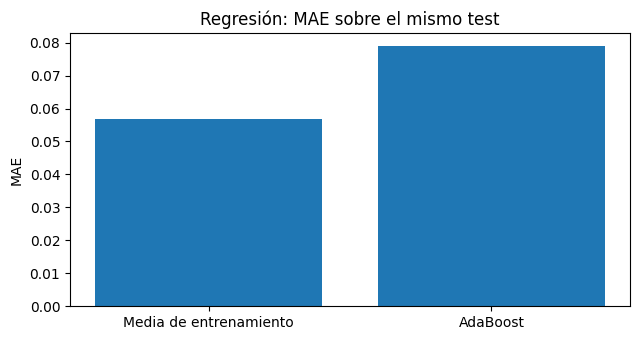

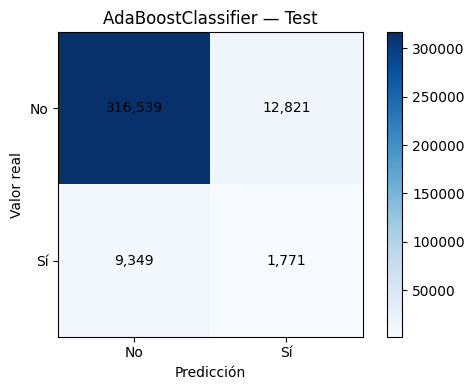

In [8]:
fig, ax = plt.subplots(figsize=(6.5,3.5))
ax.bar(['Media de entrenamiento','AdaBoost'], [baseline_reg['MAE'],metricas_reg['MAE']])
ax.set_ylabel('MAE')
ax.set_title('Regresión: MAE sobre el mismo test')
fig.tight_layout()
fig.savefig(CARPETA_RESULTADOS/'comparacion_mae.png',dpi=130)
plt.show()

cm=confusion_matrix(y_test_clf,pred_clf,labels=[0,1])
fig, ax=plt.subplots(figsize=(5.5,4))
im=ax.imshow(cm,cmap='Blues')
for (i,j),v in np.ndenumerate(cm):
    ax.text(j,i,f'{v:,}',ha='center',va='center')
ax.set_xticks([0,1],labels=['No','Sí'])
ax.set_yticks([0,1],labels=['No','Sí'])
ax.set_xlabel('Predicción')
ax.set_ylabel('Valor real')
ax.set_title('AdaBoostClassifier — Test')
fig.colorbar(im,ax=ax)
fig.tight_layout()
fig.savefig(CARPETA_RESULTADOS/'matriz_confusion.png',dpi=130)
plt.show()

## 9. Exportación de parámetros, métricas, predicciones y modelos

Todos los archivos se almacenan **directamente en Drive** bajo `ModelLOA/Resultados/AdaBoost_Semana6`. Se adjuntan hash de entrada, versión de librerías, periodos y tamaño de las muestras de entrenamiento.

In [9]:
predicciones = DF.iloc[ix_test][CLAVE+[TARGET_REG,TARGET_CLF]].copy()
predicciones['prediccion_homicidios_adaboost'] = pred_reg
predicciones['puntuacion_clase_positiva'] = pred_prob
predicciones['prediccion_binaria_adaboost'] = pred_clf
predicciones.to_csv(CARPETA_RESULTADOS/'predicciones_adaboost.csv.gz',
                    index=False,compression='gzip',float_format='%.12g')
validacion_reg.to_csv(CARPETA_RESULTADOS/'busqueda_regresion.csv',index=False)
validacion_clf.to_csv(CARPETA_RESULTADOS/'busqueda_clasificacion.csv',index=False)
pd.DataFrame([metricas_reg]).to_csv(CARPETA_RESULTADOS/'metricas_regresion.csv',index=False)
pd.DataFrame([metricas_clf]).to_csv(CARPETA_RESULTADOS/'metricas_clasificacion.csv',index=False)
joblib.dump(pre_final,CARPETA_RESULTADOS/'preprocesador_adaboost.joblib')
joblib.dump(modelo_reg,CARPETA_RESULTADOS/'adaboost_regresor.joblib')
joblib.dump(modelo_clf,CARPETA_RESULTADOS/'adaboost_clasificador.joblib')

manifest = {
    'generado_utc':datetime.now(timezone.utc).isoformat(),
    'ruta_entrada':str(ARCHIVO_DATOS),
    'sha256_csv':HASH_ENTRADA,
    'filas_entrada':int(len(DF)),
    'inicio':str(DF['fecha'].min().date()),
    'fin':str(DF['fecha'].max().date()),
    'fecha_validacion':str(FECHA_VALIDACION.date()),
    'fecha_prueba':str(FECHA_TEST.date()),
    'filas_subentrenamiento':int(len(ix_sub)),
    'filas_entrenamiento_final':int(len(ix_train)),
    'filas_validacion':int(len(ix_val)),
    'filas_test':int(len(ix_test)),
    'semilla':SEMILLA,
    'predictoras':PREDICTORAS,
    'objetivos':[TARGET_REG,TARGET_CLF],
    'mejor_regresor':GANADOR_REG,
    'mejor_clasificador':GANADOR_CLF,
    'umbral':UMBRAL_FINAL,
    'tolerancia_umbral':TOLERANCIA_UMBRAL,
    'metricas_regresion_test':metricas_reg,
    'metricas_clasificacion_test':metricas_clf,
    'python':platform.python_version(),
    'scikit_learn':sklearn.__version__,
    'pandas':pd.__version__,
    'numpy':np.__version__,
}
(CARPETA_RESULTADOS/'manifiesto_adaboost.json').write_text(
    json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('Archivos guardados en:',CARPETA_RESULTADOS)
display(predicciones.head(10))

Archivos guardados en: /content/drive/MyDrive/ModelLOA/Resultados/AdaBoost_Semana6


,codigo_provincia,codigo_distrito,fecha,franja_horaria,total_homicidios,hubo_homicidios,prediccion_homicidios_adaboost,puntuacion_clase_positiva,prediccion_binaria_adaboost
16072,01,01D01,2025-01-01,madrugada,0,0,0.032878,0.623069,0
16073,01,01D01,2025-01-01,manana,0,0,0.032878,0.623069,0
16074,01,01D01,2025-01-01,noche,0,0,0.032878,0.652012,0
16075,01,01D01,2025-01-01,tarde,0,0,0.032878,0.623069,0
16076,01,01D01,2025-01-02,madrugada,0,0,0.032878,0.623069,0
16077,01,01D01,2025-01-02,manana,0,0,0.032878,0.623069,0
16078,01,01D01,2025-01-02,noche,0,0,0.032878,0.652012,0
16079,01,01D01,2025-01-02,tarde,0,0,0.032878,0.623069,0
16080,01,01D01,2025-01-03,madrugada,0,0,0.032878,0.623069,0
16081,01,01D01,2025-01-03,manana,0,0,0.032878,0.623069,0


## 10. Comprobación de reproducibilidad

Los modelos y el preprocesador se vuelven a cargar desde Drive y se verifica que reproduzcan las predicciones del test. La comprobación confirma la consistencia de los artefactos guardados, **no** la completitud de las fuentes oficiales.

In [10]:
pre_cargado=joblib.load(CARPETA_RESULTADOS/'preprocesador_adaboost.joblib')
reg_cargado=joblib.load(CARPETA_RESULTADOS/'adaboost_regresor.joblib')
clf_cargado=joblib.load(CARPETA_RESULTADOS/'adaboost_clasificador.joblib')
X_verif=pre_cargado.transform(DF.iloc[ix_test][PREDICTORAS])
reg_verif=np.maximum(reg_cargado.predict(X_verif),0)
prob_verif=clf_cargado.predict_proba(X_verif)[:,1]
clf_verif=decisiones(prob_verif,UMBRAL_FINAL)

verificado = (
    np.allclose(reg_verif,pred_reg,rtol=0,atol=1e-9)
    and np.allclose(prob_verif,pred_prob,rtol=0,atol=1e-12)
    and np.array_equal(clf_verif,pred_clf)
    and sha256_archivo(ARCHIVO_DATOS)==HASH_ENTRADA
)
if not verificado:
    raise AssertionError('No coincidieron los artefactos recargados o cambió el CSV.')
(CARPETA_RESULTADOS/'verificacion_adaboost.json').write_text(
    json.dumps({'estado':'VERIFICADO','filas_comparadas':len(ix_test),
                'sha256_entrada':HASH_ENTRADA},indent=2),encoding='utf-8')
print(f'VERIFICADO: {len(ix_test):,} predicciones de prueba para ambos modelos.')

VERIFICADO: 340,480 predicciones de prueba para ambos modelos.
